# CheckMate — Nivolumab: Multi-Omic Analysis Cohort
**Source:** Braun et al., *Nature Medicine* 2020 — `41591_2020_839_MOESM2_ESM.xlsx`  
**Scope:** Nivolumab arm · patients with data in WES, RNA evaluable ORR only  


| Module | File | Role |
|---|---|---|
| `utils` | `src/utils/utils.py` | I/O, cohort building, survival, mutations |
| `plots` | `src/utils/plots.py` | histograms, response bar/box, categorical box, corr heatmap, missing heatmap |
| `data_formatting` | `src/utils/data_formatting.py` | `extract_patient_info`, `match_patients` |

In [1]:
# ── Paths & sys.path ───────────────────────────────────────────────────────
import sys, pathlib, warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = pathlib.Path().resolve().parent   # notebooks/ → project root
SRC_PATH     = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

XLSX = PROJECT_ROOT / 'response-prediction'/'data' / 'raw' / 'Checkmate' / '41591_2020_839_MOESM2_ESM.xlsx'

SHEETS_TO_MATCH = [
    'S2_WES_Data',
    'S4A_RNA_Expression'
]

print('Project root:', PROJECT_ROOT)
print('XLSX exists :', XLSX.exists())

Project root: /Users/rubysharma/Library/CloudStorage/Dropbox
XLSX exists : True


In [3]:
# ── Imports ────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from scipy import stats
import re
from collections import Counter
import seaborn as sns

# ── Project utilities ──────────────────────────────────────────────────────
from src.utils.plots import (
    plot_histograms, 
    plot_response_barplots,
    plot_response_boxplots, 
    plot_expression_qc, 
    plot_categorical_boxplot,
    missin_val_heatmap, 
    plot_clinical_pca )

from src.utils.data_formatting import ( standarize_sex_colum, 
                                        extract_patient_info,
                                        match_patients )
from src.utils.config import load_config

from src.utils.helper_func import mahalanobis_outliers, compute_pca_scores,  cohort_characterisation_table

sns.set_theme(style='whitegrid', font_scale=1.05)
print('Imports OK.')

Imports OK.


In [4]:
# ── Load Configurations ────────────────────────────────────────────────────────────────
args = {"config":"configs/Params_set.yml"}

cfg = load_config(args["config"])


In [5]:
pd.set_option('display.max_columns', None)

---
## PART A — Cohort Construction
### A1. Load Full Dataset 

In [6]:

# clinical data of advanced ccRCC patients
Ckm_clinical_data = pd.read_excel("data/raw/CheckMate/41591_2020_839_MOESM2_ESM.xlsx", sheet_name="S1_Clinical_and_Immune_Data", header=1)

# Rna expression
Ckm_rna_exp = pd.read_excel("data/raw/CheckMate/41591_2020_839_MOESM2_ESM.xlsx", sheet_name=SHEETS_TO_MATCH[1], header=1)





In [7]:
#  ── standardizing the column sex ────────────────────────────────────────────────────────────
Ckm_clinical_data = standarize_sex_colum(Ckm_clinical_data, "Sex")
Ckm_clinical_data["Sex"].unique()

array(['Male', 'Female'], dtype=object)

In [8]:
# ── Cohort and arm summary of clinical data ────────────────────────────────────────────────────
extract_patient_info(Ckm_clinical_data)  # from data_formatting.py

No of unique subjects: 1006
No of unique cohorts: 3 - ['CM-010' 'CM-025' 'CM-009']
No of unique arms: 2 - ['NIVOLUMAB' 'EVEROLIMUS']
No of patients with IMDC score: 803
Number of responders and non-responder: ORR
SD                                       448
PD                                       322
CRPR                                     111
NE                                        80
PR                                        40
CR                                         3
EARLY DISCONTINUATION DUE TO TOXICITY      1
NEVER TREATED                              1
Name: count, dtype: int64
Sample Type: SampleType
FFPE      971
FROZEN     35
Name: count, dtype: int64


### A2. Select Nivolumab arm only

In [9]:
Ckm_clinical_nivo = Ckm_clinical_data.loc[Ckm_clinical_data["Arm"] == "NIVOLUMAB",:]

### A3. Remove patients who are never treated and discontinuted due to toxicity

In [10]:
Ckm_clinical_nivo = Ckm_clinical_nivo.loc[Ckm_clinical_nivo["ORR"].isin(["PD", "SD", "PR", "CRPR", "CR"])]

In [11]:
# ── Cohort and arm summary of nivolumab treated patients ────────────────────────────────────────────────────────────────
extract_patient_info(Ckm_clinical_nivo)  # from data_formatting.py

No of unique subjects: 577
No of unique cohorts: 3 - ['CM-010' 'CM-025' 'CM-009']
No of unique arms: 1 - ['NIVOLUMAB']
No of patients with IMDC score: 376
Number of responders and non-responder: ORR
SD      224
PD      216
CRPR     94
PR       40
CR        3
Name: count, dtype: int64
Sample Type: SampleType
FFPE      542
FROZEN     35
Name: count, dtype: int64


### A4. Select patients with RNA exp

In [12]:
matcd_ids = match_patients(Ckm_clinical_nivo, "RNA_ID", Ckm_rna_exp.columns )
Fil_Ckm_rna_exp = Ckm_rna_exp.iloc[:,[0]+matcd_ids]
Ckm_clinical_rna_exp = Ckm_clinical_nivo[Ckm_clinical_nivo["RNA_ID"].isin(Fil_Ckm_rna_exp.columns)]

assert Ckm_clinical_rna_exp["RNA_ID"].isnull().sum()==0, f"No null RNA_ID should be present in the clinical rna expression data"

common_patients = set(Ckm_clinical_rna_exp["SUBJID"])  
Filt_Ckm_clinical = Ckm_clinical_data.loc[Ckm_clinical_data["SUBJID"].isin(common_patients)]


In [13]:
extract_patient_info(Filt_Ckm_clinical)

No of unique subjects: 172
No of unique cohorts: 3 - ['CM-010' 'CM-025' 'CM-009']
No of unique arms: 1 - ['NIVOLUMAB']
No of patients with IMDC score: 111
Number of responders and non-responder: ORR
PD      69
SD      64
CRPR    25
PR      13
CR       1
Name: count, dtype: int64
Sample Type: SampleType
FFPE      156
FROZEN     16
Name: count, dtype: int64


### A5. Missing Data Map (within analysis cohort)

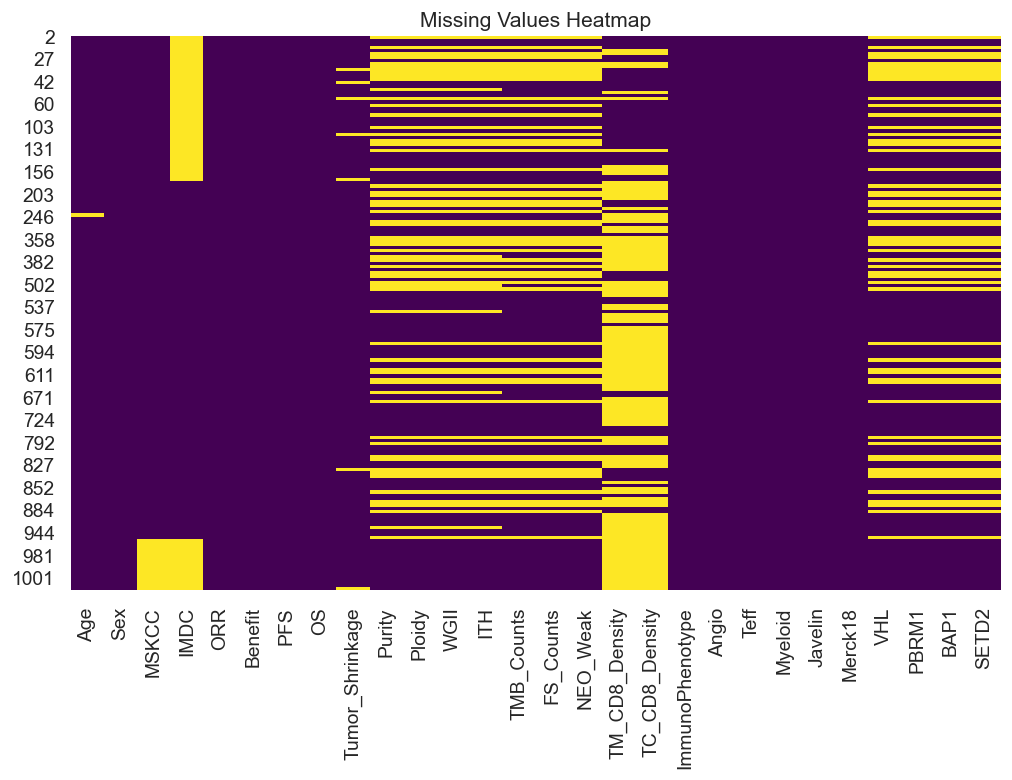

Remaining missing data in analysis cohort:
TM_CD8_Density     63.4
TC_CD8_Density     63.4
WGII               36.0
Purity             36.0
Ploidy             36.0
ITH                36.0
IMDC               35.5
SETD2              32.6
TMB_Counts         32.6
BAP1               32.6
FS_Counts          32.6
NEO_Weak           32.6
PBRM1              32.6
VHL                32.6
MSKCC               9.3
Tumor_Shrinkage     4.1
Age                 0.6


In [14]:
# ── missin_val_heatmap from plots.py ───────────────────────────────────────
key_cols = [c for c in [
    'Age','Sex','MSKCC','IMDC',
    'ORR','Benefit','PFS','OS','Tumor_Shrinkage',
    'Purity','Ploidy','WGII','ITH',
    'TMB_Counts','FS_Counts','NEO_Weak',
    'TM_CD8_Density','TC_CD8_Density','ImmunoPhenotype',
    'Angio','Teff','Myeloid','Javelin','Merck18',
    'VHL','PBRM1','BAP1','SETD2',
] if c in Filt_Ckm_clinical.columns]

missin_val_heatmap(Filt_Ckm_clinical[key_cols])

miss_pct = Filt_Ckm_clinical[key_cols].isnull().mean().mul(100).sort_values(ascending=False).round(1)
miss_pct = miss_pct[miss_pct > 0]
if len(miss_pct):
    print('Remaining missing data in analysis cohort:')
    print(miss_pct.to_string())
else:
    print('No missing values in key columns — cohort is fully matched.')

---
## PART B — Classifying patients as Responders and Non-Responders

### B1. Tumor shrinkage per ORR category
#### Complete response and parital response patients have tumor shrinkage. However, some of the stable disease and progressive diseas patients also show tumor shrinkage with nivolumab treatment.

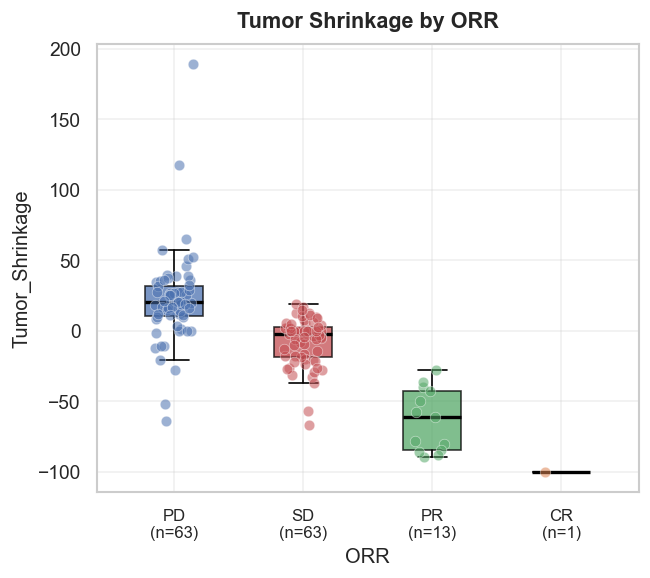

In [15]:
fig = plot_categorical_boxplot(Filt_Ckm_clinical, "ORR", "Tumor_Shrinkage",order=["PD", "SD", "PR", "CR"],  show = True,  title = "Tumor Shrinkage by ORR")

### B2. Progression free survival per ORR category
### Complete response and parital response patients have progression free survival more than six months. Few patients of stable disease and progressive disease has progression free survival of 6 months.

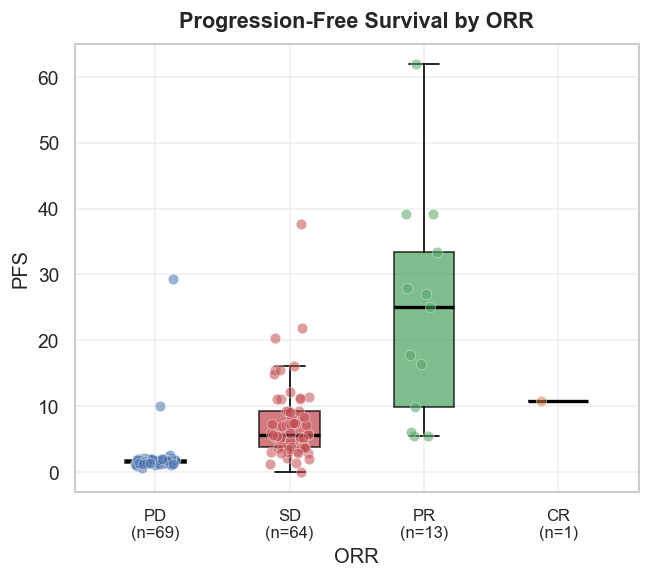

In [16]:
fig = plot_categorical_boxplot(Filt_Ckm_clinical, "ORR", "PFS",order=["PD", "SD", "PR", "CR"],  show = True,  title = "Progression-Free Survival by ORR")

In [17]:
Filt_Ckm_clinical[["ORR"]].value_counts()

ORR 
PD      69
SD      64
CRPR    25
PR      13
CR       1
Name: count, dtype: int64

### B4. In order to avoid ambiguity introduced by SD patients, due to overlap with PD and (PR,CR) both in terms of tumor shrinkage and progression free survival, we are only focusing on PD, PR and CR patients. 

In [18]:
Filt_Ckm_clinical = Filt_Ckm_clinical.loc[Filt_Ckm_clinical["ORR"].isin(["PD", "CR", "PR", "CRPR"]), :]

### B5. For our analysis we are categorizing PR (partial response), CR (complete response) patients as responders and PD (progressive disease) patients as non-responders.

In [19]:
Filt_Ckm_clinical.loc[Filt_Ckm_clinical["ORR"].isin(["CR", "PR", "CRPR"]), "Response"] = "Responders"
Filt_Ckm_clinical.loc[Filt_Ckm_clinical["ORR"].isin(["PD"]), "Response"] = "Non-Responders"

In [20]:

Final_rna_exp  =  Fil_Ckm_rna_exp.loc[:, Fil_Ckm_rna_exp.columns.isin(Filt_Ckm_clinical["RNA_ID"])]
Final_rna_exp.insert(0, "gene_name",Fil_Ckm_rna_exp.iloc[:,0] )

In [21]:
with pd.ExcelWriter("data/processed/CheckMate_Nivolumab_patients_clincal_rnaexp.xlsx", engine="openpyxl") as writer:
    Filt_Ckm_clinical.to_excel(writer, sheet_name="clinical_data", index=False)
    Final_rna_exp.to_excel(writer, sheet_name="RNA_exp", index=False)

In [22]:
Filt_Ckm_clinical.head()

,SUBJID,Cohort,Arm,MAF_Tumor_ID,MAF_Normal_ID,CNV_ID,RNA_ID,CD8_IF_ID,Sex,Age,MSKCC,IMDC,Sarc,Rhab,Sarc_or_Rhab,Received_Prior_Therapy,Number_of_Prior_Therapies,Days_from_TumorSample_Collection_and_Start_of_Trial_Therapy,SampleType,Tumor_Sample_Primary_or_Metastasis,Site_of_Metastasis,Tumor_Shrinkage,ORR,Benefit,ExtremeResponder,PFS,PFS_CNSR,OS,OS_CNSR,irORR,irPFS,irPFS_CNSR,Purity,Ploidy,TM_Area,TM_CD8,TM_CD8_Density,TC_Area,TC_CD8,TC_CD8_Density,TM_TC_Ratio,ImmunoPhenotype,TM_CD8_PERCENT,TC_CD8_PERCENT,TMB_Counts,FS_Counts,NEO_Weak,WGII,ITH,homozygous_ANY,Amplification_1p36.32,Amplification_1q21.3,Amplification_1q32.1,Amplification_2q37.3,Amplification_5p15.33,Amplification_5q31.3,Amplification_5q35.3,Amplification_6p21.2,Amplification_6q21,Amplification_7p22.2,Amplification_7q36.2,Amplification_8p11.21,Amplification_8q24.3,Amplification_9q34.11,Amplification_11q13.3,Amplification_11q14.1,Amplification_12q24.32,Amplification_17q21.2,Amplification_17q25.3,Amplification_20q13.33,Amplification_21q22.3,Deletion_1p36.31,Deletion_1p36.11,Deletion_1q42.3,Deletion_2q37.1,Deletion_3p21.1,Deletion_5q14.1,Deletion_6p22.2,Deletion_6p21.32,Deletion_6p12.1,Deletion_6q25.2,Deletion_8p23.2,Deletion_9p21.3,Deletion_9q34.3,Deletion_10q23.31,Deletion_10q26.3,Deletion_11q12.3,Deletion_11q23.1,Deletion_12q24.33,Deletion_14q32.33,Deletion_15q11.2,Deletion_19p13.3,Deletion_19q13.42,Deletion_22q11.21,ARID1A,ATM,BAP1,COL9A3,KDM5C,MTOR,NF2,PBRM1,PCK1,PIK3CA,PTEN,S100B,SETD2,SMARCA4,TCEB1,TP53,TRMT2B,TSC1,USP32,VHL,WNT8A,ZNF800,Angio,Teff,Myeloid,Javelin,Merck18,Response
4,RCC10-97,CM-010,NIVOLUMAB,RP-1458_RCCBMS-00097-T_v4_Exome_OnPrem,RP-1458_RCCBMS-00097-N_v1_Exome_OnPrem,RCCBMS-00097-T.called.seg,G138701_RCCBMS-00097-T_v1_RNA_OnPrem,0001 00097,Female,67.0,FAVORABLE,NaN,0.0,0.0,0.0,Yes,2.0,254.0,FFPE,PRIMARY,NaN,-40.000000,PR,CB,NEITHER,5.490411,1,36.526027,1,irPR,5.490411,0.0,0.49,1.99,11.13455,1339.0,120.256319,171.93645,26739.0,155.516762,0.773269,Infiltrated,NaN,NaN,45.0,6.0,247.0,0.094628,2.018182,0.0,WT,WT,WT,WT,MUT,MUT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,MUT,WT,WT,WT,MUT,MUT,MUT,WT,WT,WT,WT,WT,MUT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,35.142149,28.844206,27.360042,30.276256,32.095831,Responders
6,RCC10-141,CM-010,NIVOLUMAB,RP-1458_RCCBMS-00141-T_v1_Exome_OnPrem,RP-1458_RCCBMS-00141-N_v1_Exome_OnPrem,RCCBMS-00141-T.called.seg,G138701_RCCBMS-00141-T_v1_RNA_OnPrem,0014 00141,Female,62.0,POOR,NaN,0.0,0.0,0.0,Yes,1.0,800.0,FFPE,PRIMARY,NaN,-89.436620,PR,CB,ER,61.906849,0,68.547945,0,irPR,61.906849,0.0,0.13,1.90,13.06570,1963.0,150.240707,17.89496,1508.0,84.269537,1.782859,Infiltrated,NaN,NaN,23.0,1.0,106.0,0.176462,0.000000,0.0,WT,WT,WT,WT,MUT,MUT,MUT,WT,WT,MUT,MUT,MUT,MUT,WT,WT,WT,MUT,WT,MUT,WT,MUT,MUT,MUT,MUT,MUT,MUT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,WT,33.952069,29.595384,32.586142,29.565893,32.010041,Responders
12,RCC10-99,CM-010,NIVOLUMAB,NaN,NaN,NaN,G138701_RCCBMS-00099-T_v1_RNA_OnPrem,0015 00099,Male,60.0,FAVORABLE,NaN,0.0,0.0,0.0,Yes,3.0,790.0,FFPE,PRIMARY,NaN,11.787072,PD,NCB,PD,1.249315,1,1.479452,1,irPD,1.249315,1.0,NaN,NaN,6.58964,801.0,121.554440,23.64866,488.0,20.635419,5.890573,Excluded,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.728524,29.221520,31.233694,30.039203,31.801720,Non-Responders
25,RCC10-116,CM-010,NIVOLUMAB,NaN,NaN,NaN,G138701_RCCBMS-00116-T_v1_RNA_OnPrem,0021 00116,Male,60.0,POOR,NaN,0.0,0.0,0.0,Yes,2.0,860.0,FFPE,PRIMARY,NaN,-51.785714,PD,NCB,PD,1.216438,1,5.950685,1,irPD,1.216438,1.0,NaN,NaN,6.66622,1015.0,152.260201,38.86463,3234.0,83.211908,1.829789,Infiltrated,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

---
## PART C — Visualizations on Analysis Cohort

##### The following picture shows the difference in distribution of clinical variables between Responders and Non-Responders. Age is significantly different between the two groups. Older patients tend to have less aggressive tumor biology and mico-environment. Tumor shrinkage is signficanlty different. Responders show tumor shrinkage while Non-responders show tumor growing. This works as a sanity check. WGII, Purity, Tm Area, ITH, Tm CD8 Density and number of prior therapies are all non-significant. Sample sizes are too small to detect the differences. Sample sizes vary across plots because of the missing data.

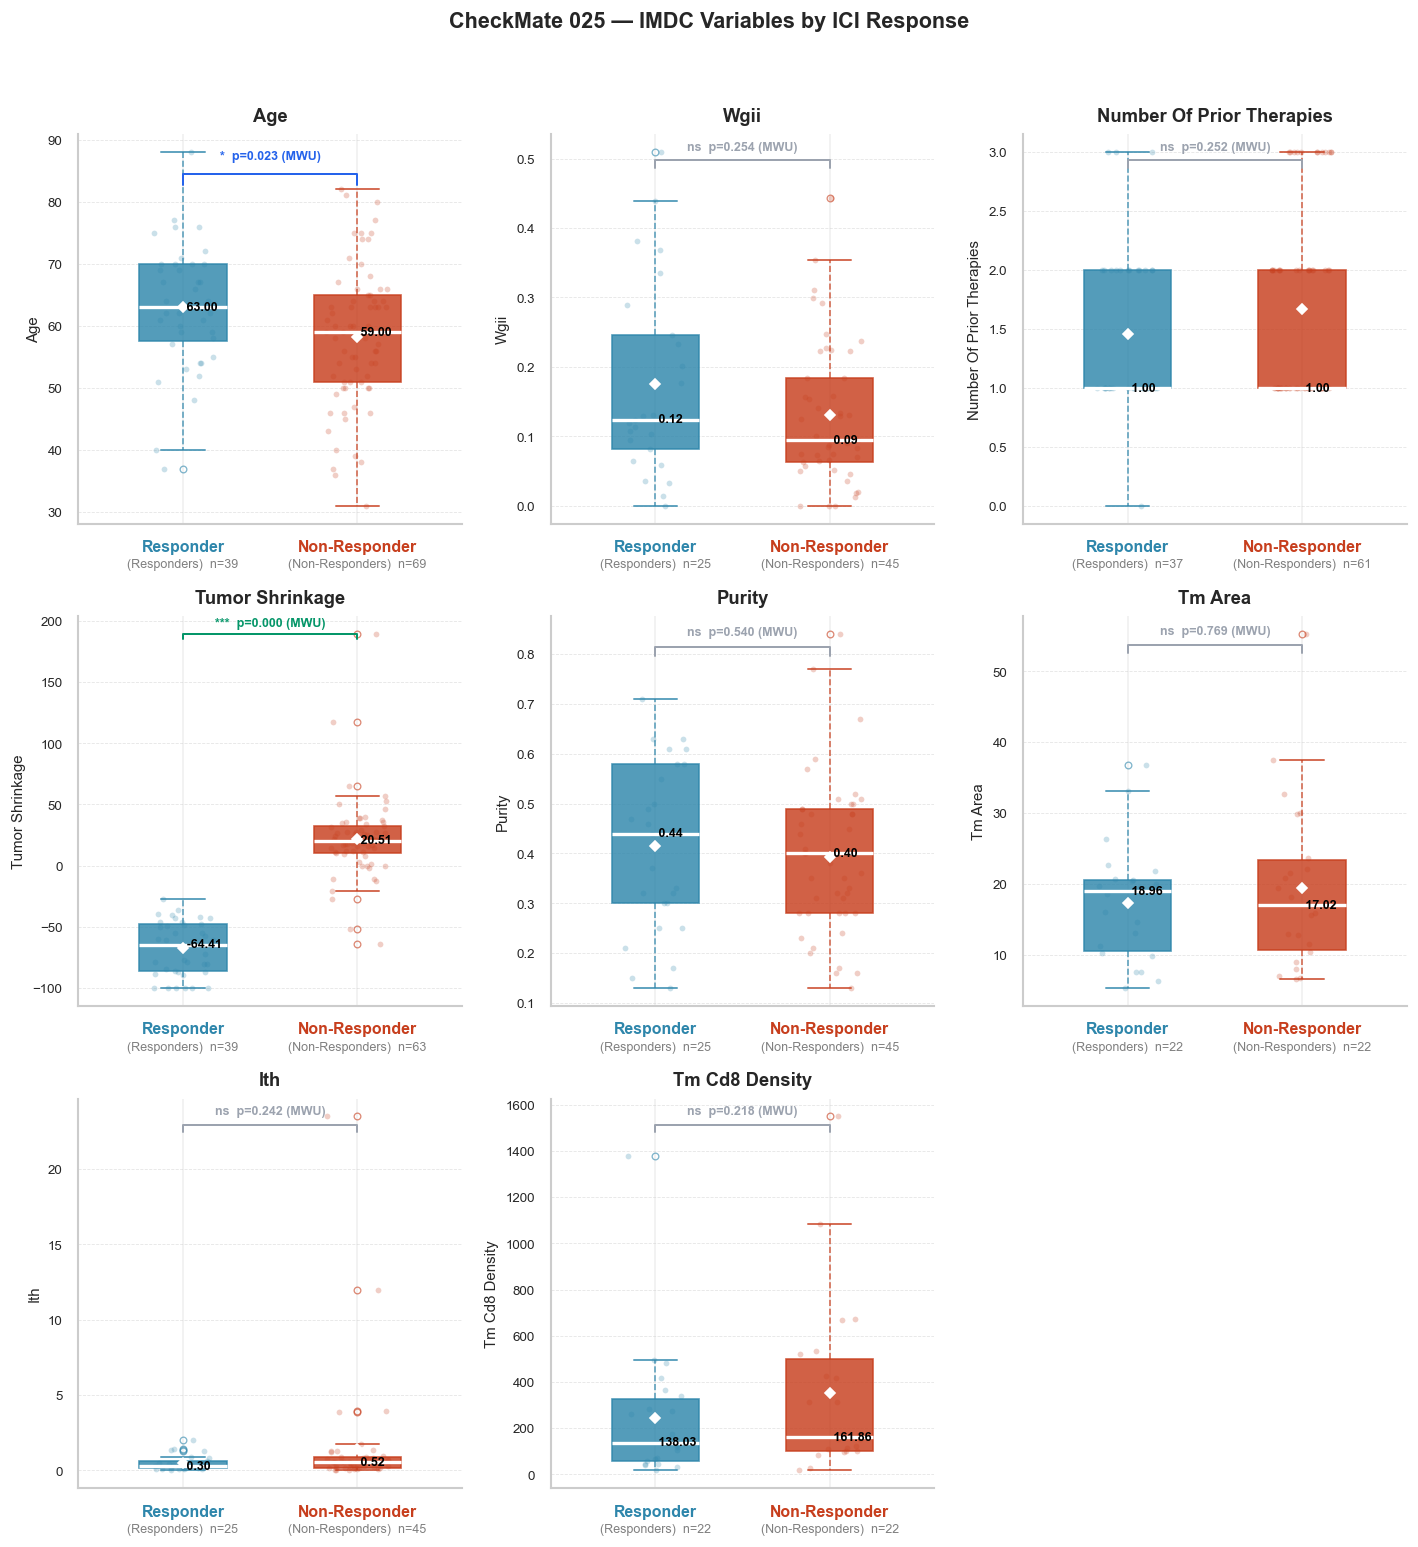

In [23]:
    
fig3 = plot_response_boxplots(
          Filt_Ckm_clinical,
          numerical_cols=["Age", "WGII", "Number_of_Prior_Therapies",
                      "Tumor_Shrinkage", "Purity", "TM_Area","ITH","TM_CD8_Density" ],
            response_col="Response",
            colors=["#2E86AB", "#C73E1D"],
            responders = ["Responders"],
            non_responders=["Non-Responders"],
            show_points="jitter",
            show_pvalue="mannwhitney",
            title="CheckMate 025 — IMDC Variables by ICI Response"
)

---
## PART D — RNA-seq quality

In [24]:

column_order = Final_rna_exp.columns[1:]
Filt_Ckm_clinical["RNA_ID"] = pd.Categorical( Filt_Ckm_clinical["RNA_ID"], categories=column_order, ordered=True)
Chkmt_clinical_filt_order =  Filt_Ckm_clinical.sort_values("RNA_ID")
Chkmt_clinical_filt_order.index = Chkmt_clinical_filt_order["SUBJID"]


In [25]:
col_names = Chkmt_clinical_filt_order.loc[Chkmt_clinical_filt_order["RNA_ID"].isin(Final_rna_exp.columns),"SUBJID"]
Final_rna_exp.columns = ["gene_name"]+col_names.tolist()


### D1. Exploratory QC was performed on the downloaded expression matrix to confirm data integrity prior to analysis

##### Library sizes are tightly clustered around the median of 1.1M counts with no extreme outliers, indicating consistent sequencing depth across samples. The expression density plot shows all samples following near-identical bimodal distributions. A low expresssion peak representing background and a higher peak representing actively expressed genes, confirming uniform data quality with no aberrant samples. The mean-variance plot shows the expected relationship where lowly expressed genes have higher variance, consistent with a well-behaved count dataset. Zero-count fractions are minimal and consistent across samples, with no sample showing unusual dropout. Overall, the expression matrix is clean and homogeneous, supporting its use for downstream signature scoring without further filtering.

[QC] PDF saved → results/qc_rnaseq/rna_seq_full_report.pdf
[QC] 4 plots saved to: /Users/rubysharma/Library/CloudStorage/Dropbox/response-prediction/results/qc_rnaseq


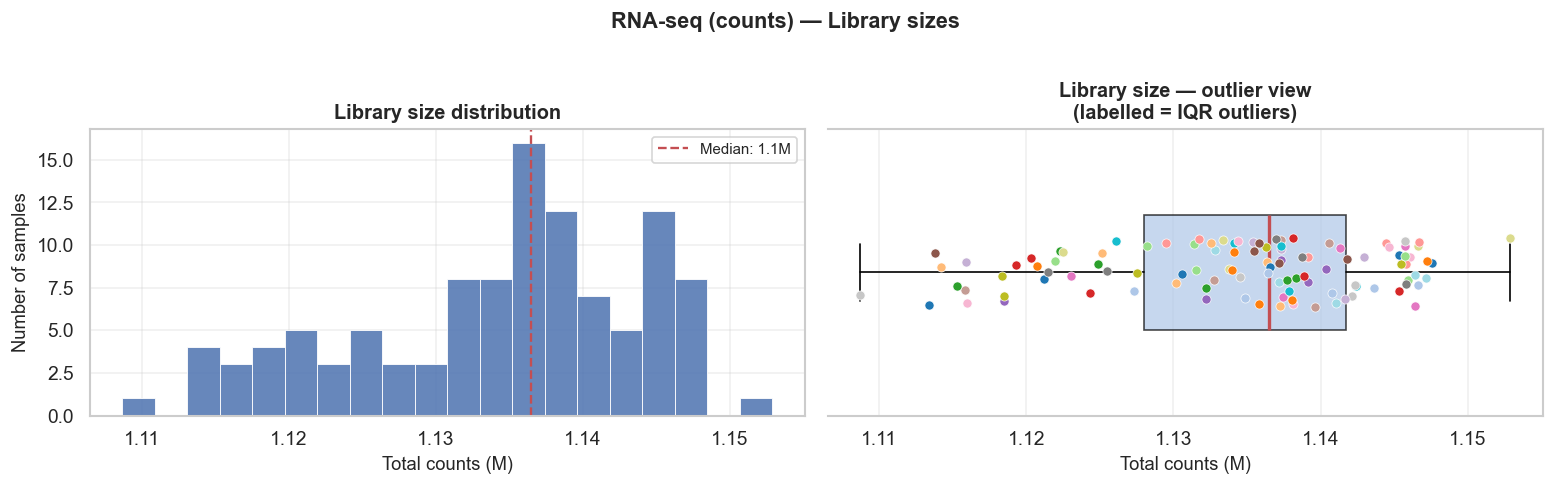

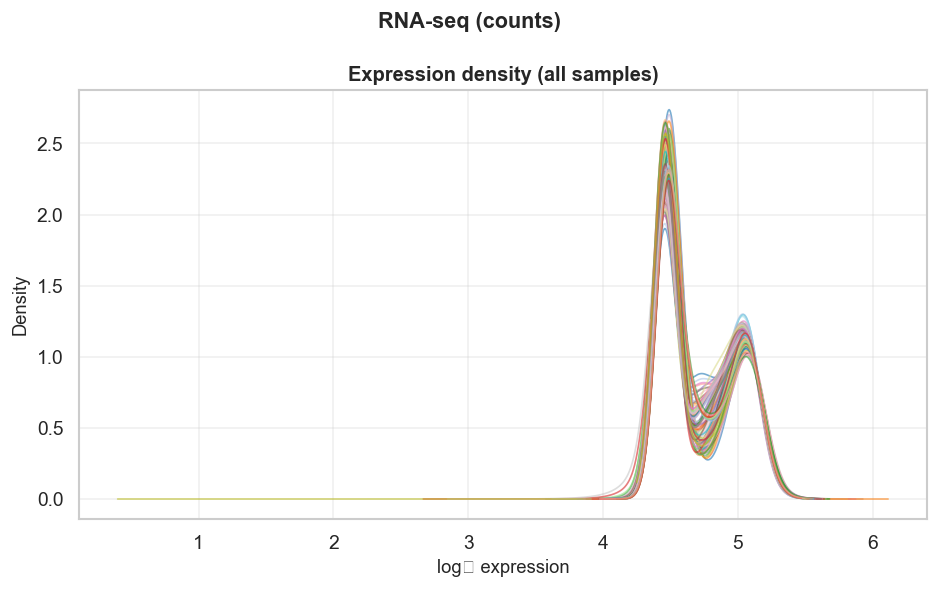

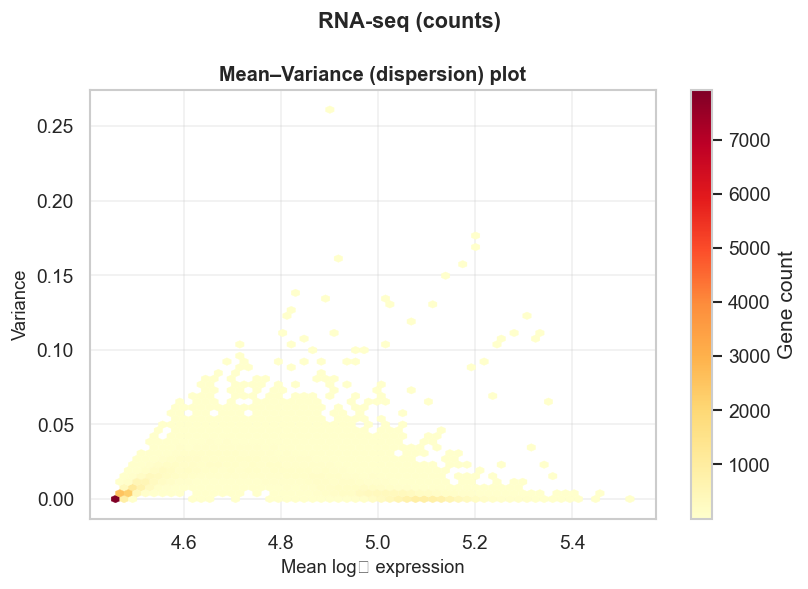

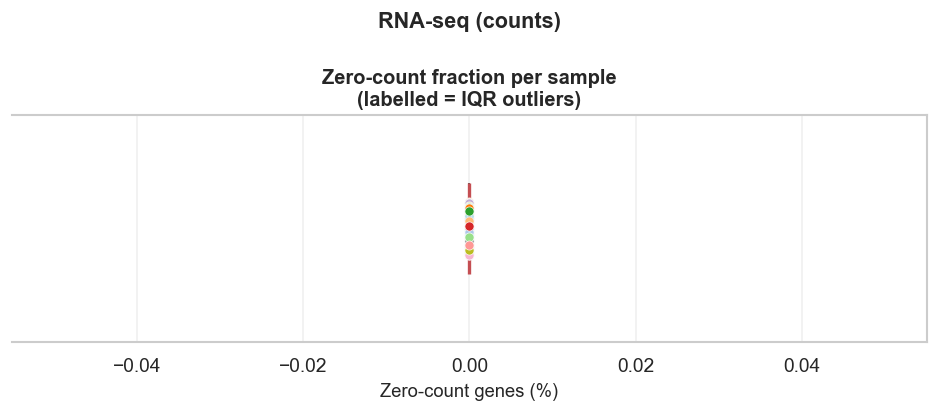

{'01_library_sizes': <Figure size 1560x480 with 2 Axes>,
 '02_density': <Figure size 960x600 with 1 Axes>,
 '03_mean_variance': <Figure size 840x600 with 2 Axes>,
 '04_zero_fraction': <Figure size 960x420 with 1 Axes>}

In [26]:
plot_expression_qc(Final_rna_exp.iloc[:,1:], data_type="rnaseq",
                       output_dir="results/qc_rnaseq",
                       prefix="rna_seq", show=True, pca_label_samples=False)

### D2. PCA plots

##### Following PCA shows the normalized RNA-seq expression variation between Responders and Non-Responders. The colors shows the Response group whereas the shapes represents different cohorts. There is no clear separation between Responders and Non-Responders which is expected as the responsible differentiating biomarkers are masked by the thousands of genes. PC1 captures only 10.1% and PC2 just 4.1% variation. Cohorts CM-009, CM-010 and CM-025 shows a dispersion, CM-009 is at the center and tightly clustered, CM010 is more spread out and CM-025 is far more dispersed which reflects three phase trials patient selection. Each phase trial has more heterogenous patient selected. Few outlier points belongs to cohort CM-025(phase-3 trial) of sarcomatoid or rhabdoid aggressive feautres. A point on the far left of PC1 and PC2 might belong to same agressive feature group however the data is not available to confirm it.

[PCA] Warning: 1 expression samples not in clinical_df — excluded: ['gene_name']
[PCA] 108 samples × 43893 features after alignment.
[PCA] Figure saved: colour=Response
[PCA] Figure saved: colour=Sarc_or_Rhab
[PCA] Figure saved: colour=ImmunoPhenotype
[PCA] PDF saved → results/checkmate/pca_clinical_pca.pdf


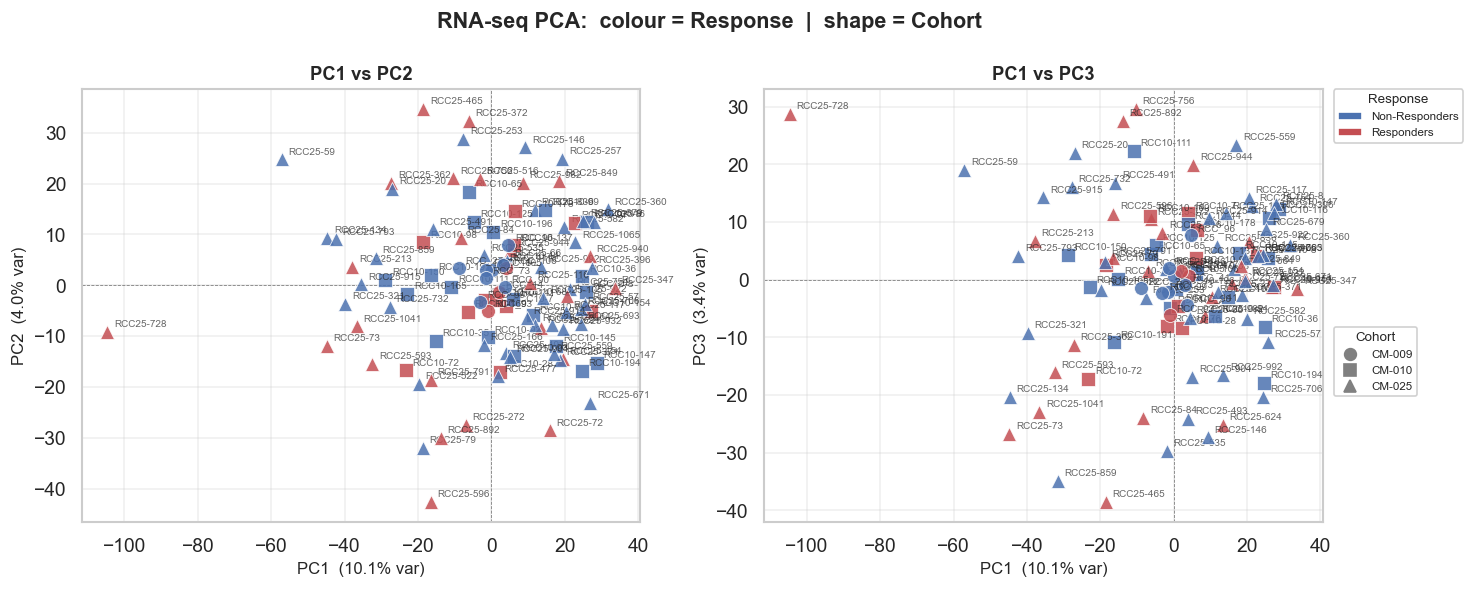

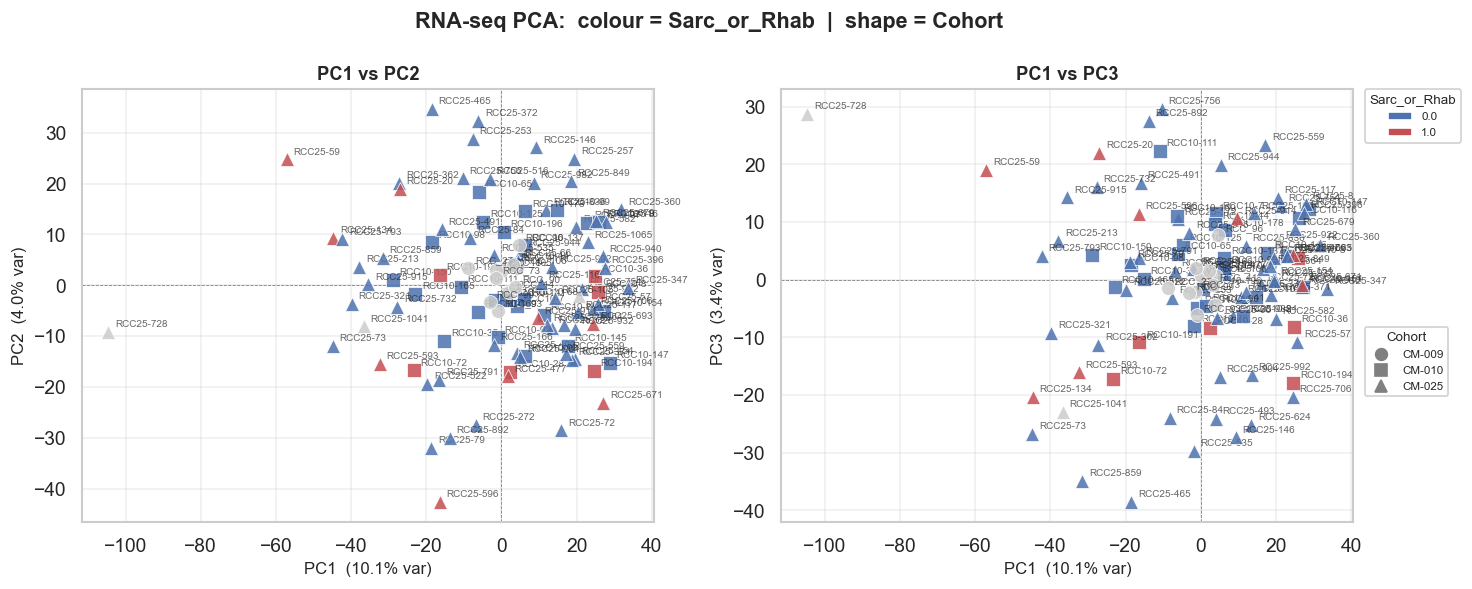

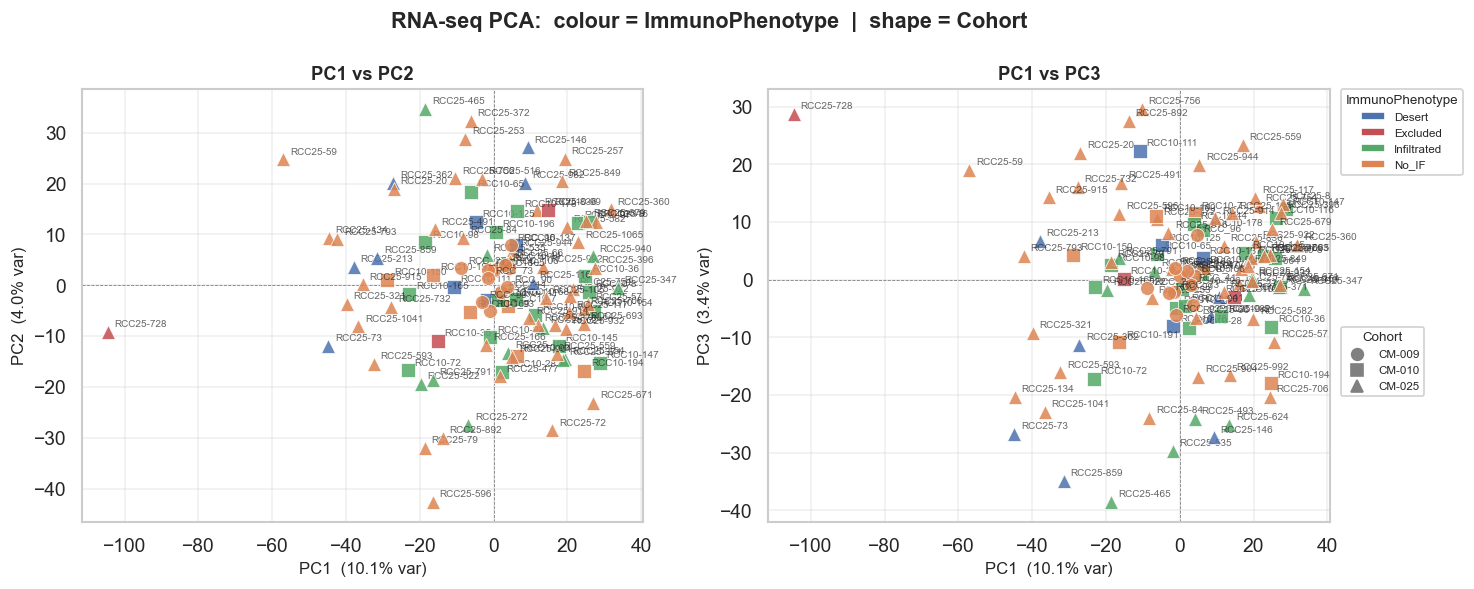

{'colour_Response': <Figure size 1440x600 with 2 Axes>,
 'colour_Sarc_or_Rhab': <Figure size 1440x600 with 2 Axes>,
 'colour_ImmunoPhenotype': <Figure size 1440x600 with 2 Axes>}

In [28]:
plot_clinical_pca(expr_df = Final_rna_exp,
    clinical_df= Chkmt_clinical_filt_order ,
    data_type = "rnaseq",
    label_samples = True,
    pcs = [(1,2), (1,3)],
    output_dir = "results/checkmate",
    color_cols = ["Response", "Sarc_or_Rhab","ImmunoPhenotype" ],
    shape_col = "Cohort")

### D3. Outlier detection

##### We are using mahalanobis distance to compute outlier by measuring the multi-dimensional distance of a data point from the centroid of a distribution.

In [29]:
# PCA computation
pca_input = Final_rna_exp
pca_input.index = Final_rna_exp.iloc[:,0]
pca_input.drop("gene_name", axis = 1, inplace = True)
pca_input = pca_input.transpose()
pca_input.columns = pca_input.columns.astype(str)
score,loading, pca = compute_pca_scores(pca_input,  n_components = 10)
is_outlier = mahalanobis_outliers(score, n_pcs=10, alpha=0.001)


PC1: 6.1% variance explained
PC2: 5.6% variance explained
PC3: 3.9% variance explained
PC4: 3.2% variance explained
PC5: 2.9% variance explained
PC6: 2.7% variance explained
PC7: 2.2% variance explained
PC8: 1.9% variance explained
PC9: 1.7% variance explained
PC10: 1.6% variance explained
Total (10 PCs): 31.7%


In [30]:
is_outlier.value_counts()

False    103
True       5
Name: count, dtype: int64

##### Five outlier samples are removed from further analysis to avoid introduction of any noise in the model development.

In [31]:
samples_of_interest = is_outlier[is_outlier].index
Outlier_rm_clinical = Chkmt_clinical_filt_order.loc[~Chkmt_clinical_filt_order["SUBJID"].isin(samples_of_interest),:]
Outlier_rm_rna_exp = Final_rna_exp[Outlier_rm_clinical["SUBJID"]]

---
### D4. Cohort Characterisation Table (Table 1) on final clinical dataset
> Stratified by Responders vs Non-Responders. Continuous features: median (IQR) + Mann-Whitney p-value. Categorical: n (%) + Chi-squared / Fisher's exact p-value.

##### Age is significantly different between Responders and Non-Responders, where median age for Non-Responders is 59.0 and 63 for Responders. PBRM1 mutation is also signifcanly different between the two groups. Responders have higher PBRM1 mutation (52%), PBRM1 loss is associated with immune infiltration and better IO response. There is no cohort bias, as both Responders and Non-Responders has same proportion of all three cohorts. Rest of the clinical features does not show any significant difference between two groups.

In [32]:
# Selected features
TABLE1_FEATURES = [
    # Demographics
    "Age", "Sex", "MSKCC", "IMDC", "Cohort", "Received_Prior_Therapy",
    # Genomic biomarkers
    "TMB_Counts", "FS_Counts", "NEO_Weak",
    # Immune / CD8
    "TM_CD8_Density", "TC_CD8_Density", "ImmunoPhenotype",
    # Gene signatures
    "Angio", "Teff", "Myeloid",
    # Genomic instability
    "Purity", "Ploidy", "WGII",
    # Top somatic mutations
    "VHL", "PBRM1", "BAP1", "SETD2",
]
# Keep only columns that actually exist in nivolumab table
TABLE1_FEATURES = [f for f in TABLE1_FEATURES if f in Outlier_rm_clinical.columns]
print(f"Features available for Table 1: {len(TABLE1_FEATURES)}")
print(TABLE1_FEATURES)

Features available for Table 1: 22
['Age', 'Sex', 'MSKCC', 'IMDC', 'Cohort', 'Received_Prior_Therapy', 'TMB_Counts', 'FS_Counts', 'NEO_Weak', 'TM_CD8_Density', 'TC_CD8_Density', 'ImmunoPhenotype', 'Angio', 'Teff', 'Myeloid', 'Purity', 'Ploidy', 'WGII', 'VHL', 'PBRM1', 'BAP1', 'SETD2']


In [33]:

df_respnse = Outlier_rm_clinical[Outlier_rm_clinical["Response"].isin(["Responders", "Non-Responders"])].copy()

tbl_strat = cohort_characterisation_table(
    df=df_respnse,
    features=TABLE1_FEATURES,
    group_col="Response",
)
display(tbl_strat)

,Feature,Category,Overall (N=103),Non-Responders (N=68),Responders (N=35),P-value
0,Age,Median (IQR),61.0 (53.0–67.0),59.0 (51.0–65.0),63.0 (57.5–70.0),0.029
1,Sex,Female,26 (25.2%),15 (22.1%),11 (31.4%),0.300
2,,Male,77 (74.8%),53 (77.9%),24 (68.6%),
3,MSKCC [11 missing],FAVORABLE,22 (23.9%),12 (20.0%),10 (31.2%),0.407
4,,INTERMEDIATE,48 (52.2%),34 (56.7%),14 (43.8%),
5,,POOR,22 (23.9%),14 (23.3%),8 (25.0%),
6,IMDC [42 missing],FAVORABLE,6 (9.8%),5 (12.5%),1 (4.8%),0.101
7,,INTERMEDIATE,34 (55.7%),18 (45.0%),16 (76.2%),
8,,NOT REPORTED,4 (6.6%),4 (10.0%),0 (0.0%),
9,,POOR,17 (27.9%),13 (32.5%),4 (19.0%),


---
## PART E — Computing gene signature score

### E1. Standardizing the genes expression by computing z-scores

In [34]:
Chkmt_exp_z = Outlier_rm_rna_exp.iloc[:,0:].apply(
    lambda x: (x - x.mean()) / x.std(),
    axis=1
)

In [35]:
Chkmt_exp_z.head(5)

,RCC25-582,RCC25-624,RCC25-982,RCC25-493,RCC25-272,RCC25-59,RCC25-72,RCC25-154,RCC25-372,RCC25-664,RCC25-754,RCC25-836,RCC25-922,RCC25-944,RCC10-7,RCC10-76,RCC10-145,RCC10-147,RCC10-150,RCC10-196,RCC10-8,RCC10-28,RCC10-35,RCC10-36,RCC10-44,RCC10-65,RCC10-68,RCC10-72,RCC10-84,RCC10-92,RCC10-93,RCC10-97,RCC10-98,RCC10-99,RCC10-111,RCC10-116,RCC10-125,RCC10-137,RCC10-141,RCC10-154,RCC10-165,RCC10-169,RCC10-178,RCC10-191,RCC10-194,RCC25-347,RCC25-593,RCC25-535,RCC25-706,RCC25-1041,RCC25-371,RCC25-57,RCC25-213,RCC25-362,RCC25-992,RCC25-84,RCC25-859,RCC25-940,RCC25-116,RCC25-793,RCC25-321,RCC25-522,RCC25-791,RCC25-146,RCC25-559,RCC25-117,RCC25-66,RCC25-105,RCC25-596,RCC25-516,RCC25-20,RCC25-166,RCC25-257,RCC25-360,RCC25-491,RCC25-8,RCC25-396,RCC25-253,RCC25-477,RCC25-79,RCC25-378,RCC25-849,RCC25-732,RCC25-693,RCC25-756,RCC25-671,RCC25-914,RCC25-1065,RCC25-932,RCC25-904,RCC25-679,RCC25-915,RCC_105,RCC_106,RCC_14,RCC_18,RCC_27,RCC_41,RCC_73,RCC_90,RCC_93,RCC_96,RCC_99
gene_name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5S_rRNA,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,0.570933,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,1.018709,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,-1.075242,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668,0.996668
7SK,1.172209,0.956585,-0.482978,-0.529901,-2.242803,0.312607,1.758159,1.024109,-0.052705,-0.823239,-0.227974,1.163477,-0.917138,0.679420,-1.227701,-0.838090,-1.990362,1.250001,-1.246251,-1.305993,1.161682,-0.229170,-1.690983,0.864183,1.001730,0.568878,-0.041460,-0.445795,0.355842,-1.324146,0.835963,1.523472,-1.787401,-0.066843,-0.398302,1.464761,-1.073421,-0.513015,0.568830,-0.574397,-0.702238,-0.259480,0.579076,-0.013950,0.619601,-0.324504,-0.381128,2.628793,0.744076,0.630077,0.366619,0.459987,0.002062,0.347737,0.382861,2.198874,2.130178,0.319351,-0.017900,-0.914234,-0.175262,-0.780128,-0.459886,1.276740,-2.140229,0.152223,0.254968,-1.542828,-1.763321,0.019991,-0.146750,-0.079919,1.649672,0.987651,-0.793284,0.794604,0.650938,1.112480,-0.754385,-0.445846,-0.587570,0.207482,-1.673195,-0.993550,-0.587838,0.225257,-1.179986,0.612427,0.970077,1.426411,0.345728,-0.203320,-0.217589,0.154026,0.103292,0.330867,-1.368225,-0.672702,-0.165989,1.582960,-0.581591,-1.131894,0.159794
A1BG,-0.535390,0.347277,-0.141771,0.104234,0.642437,-0.991100,0.875552,0.566830,0.258473,-0.024087,0.534939,-0.185604,-0.366311,-0.034328,-0.143689,-0.982978,0.150676,0.833193,1.036104,0.295008,0.360170,0.493334,0.683799,-0.122777,0.981218,0.104958,1.102726,0.435152,0.405001,0.636478,1.049332,-0.136708,-0.025707,0.112966,0.903567,-0.540348,0.961474,0.638533,-0.335274,0.429669,-4.201977,0.405260,0.325775,-0.551681,0.851903,-0.096415,0.503114,-1.070022,0.003358,0.873938,0.011446,0.521703,1.522631,-3.208110,0.031797,-0.171288,-0.572705,0.556400,-0.248015,0.429009,0.553845,0.061056,0.178749,-1.009101,0.689960,1.224142,0.283381,-0.155038,1.148886,-0.545481,-3.127811,0.567789,-0.827413,-0.258262,-0.388306,0.186930,-0.719884,0.603964,0.056899,-0.507601,-1.199251,-0.534363,0.801409,0.191098,-0.525397,0.735958,0.989256,-0.467609,0.628605,-0.184812,-0.351662,-3.487558,0.664414,-1.846501,0.064629,2.232989,-1.846501,-0.661734,0.102497,1.197866,

### E2. Computing gene-signature scores
##### Published gene signatures were used as features rather than individual genes to improve stability, interpretability, and to allow comparison across the RNA-seq training data and microarray validation cohort. 

In [36]:
Chkmt_gene_sig_score = pd.DataFrame(index =cfg["Gene_signatures"].keys() , columns=Chkmt_exp_z.columns )
Chkmt_gene_sig_score = Chkmt_gene_sig_score.fillna(0)


for gene_sig in cfg["Gene_signatures"].keys():
   
    gene_sig_exp = Chkmt_exp_z.loc[Outlier_rm_rna_exp.index.isin(cfg["Gene_signatures"][gene_sig]),:]
    if gene_sig_exp.shape[0] != 0:
        column_sum = gene_sig_exp.sum()/gene_sig_exp.shape[0]
        Chkmt_gene_sig_score.loc[gene_sig] = column_sum.to_list()


Chkmt_gene_sig_score

,RCC25-582,RCC25-624,RCC25-982,RCC25-493,RCC25-272,RCC25-59,RCC25-72,RCC25-154,RCC25-372,RCC25-664,RCC25-754,RCC25-836,RCC25-922,RCC25-944,RCC10-7,RCC10-76,RCC10-145,RCC10-147,RCC10-150,RCC10-196,RCC10-8,RCC10-28,RCC10-35,RCC10-36,RCC10-44,RCC10-65,RCC10-68,RCC10-72,RCC10-84,RCC10-92,RCC10-93,RCC10-97,RCC10-98,RCC10-99,RCC10-111,RCC10-116,RCC10-125,RCC10-137,RCC10-141,RCC10-154,RCC10-165,RCC10-169,RCC10-178,RCC10-191,RCC10-194,RCC25-347,RCC25-593,RCC25-535,RCC25-706,RCC25-1041,RCC25-371,RCC25-57,RCC25-213,RCC25-362,RCC25-992,RCC25-84,RCC25-859,RCC25-940,RCC25-116,RCC25-793,RCC25-321,RCC25-522,RCC25-791,RCC25-146,RCC25-559,RCC25-117,RCC25-66,RCC25-105,RCC25-596,RCC25-516,RCC25-20,RCC25-166,RCC25-257,RCC25-360,RCC25-491,RCC25-8,RCC25-396,RCC25-253,RCC25-477,RCC25-79,RCC25-378,RCC25-849,RCC25-732,RCC25-693,RCC25-756,RCC25-671,RCC25-914,RCC25-1065,RCC25-932,RCC25-904,RCC25-679,RCC25-915,RCC_105,RCC_106,RCC_14,RCC_18,RCC_27,RCC_41,RCC_73,RCC_90,RCC_93,RCC_96,RCC_99
T_effector,0.148237,1.174420,-0.260588,0.035187,1.560963,-0.008792,0.411303,0.167135,-1.337152,0.315283,0.278290,-0.346354,0.269590,0.588642,-1.018394,0.005230,0.476686,0.915213,-1.537171,0.336009,0.384265,1.065109,-0.900563,1.241972,-0.488197,0.854239,-0.278729,1.750031,-0.169688,0.346611,0.895233,-0.321726,-0.153865,-0.222767,-0.279078,-0.763044,-0.407575,-0.397323,0.021347,0.517137,0.692845,-0.231497,-0.396988,-0.683033,0.629775,0.100537,-0.627389,-0.210238,1.610496,0.470279,0.157589,0.419421,-0.368301,-0.953349,-0.441509,0.536741,0.179172,-0.092520,0.296506,0.565624,1.236330,0.176783,0.343554,-0.422759,0.012562,1.243788,-0.029671,0.098781,0.775775,-0.080444,-1.221828,-0.983988,-0.654707,0.315338,-0.719516,0.448606,-0.153154,-0.053567,0.048412,-0.320390,-0.380925,-1.088823,0.079113,-0.824319,-0.600074,1.519362,-0.285401,0.064541,-0.502695,-1.025273,-0.391468,-1.311144,-0.952149,-0.617076,0.823308,-0.702225,-0.451770,1.139644,-1.773695,0.304895,0.478581,-0.345363,0.261770
Angiogenesis,0.207268,-0.074041,0.973303,-0.310847,-0.515835,0.857202,-0.858317,-0.333392,1.110329,-0.422155,0.381518,1.051262,0.147333,-0.042830,-0.181768,0.310407,-1.267514,-0.327260,-3.146067,0.417905,0.855074,-2.417467,0.044701,-0.370681,0.763079,0.703026,0.545176,-0.659750,-0.267460,0.110868,-0.342572,0.667597,0.543079,1.016183,0.174285,-0.291317,1.105314,0.312488,-0.186965,0.110689,0.452573,0.087674,-0.103616,0.394477,-1.288162,-0.944248,-1.565171,0.335352,-0.199759,-1.457014,-0.317918,0.006995,0.699002,0.622280,0.014941,-0.505719,-0.402833,0.452847,0.342269,-0.547137,0.300533,0.630238,0.718739,0.214738,-0.171783,0.490953,0.727322,-0.376053,0.284889,0.786806,0.974602,-0.406015,0.874421,0.520254,0.186984,0.694043,0.101122,0.951151,-0.461819,-1.392070,-0.966582,0.717351,-0.175829,-0.047899,-0.239382,-0.372129,-0.045331,0.422332,-0.975003,-1.321401,0.385567,0.288476,-0.624273,0.975770,-0.064143,-0.191218,0.833934,0.115189,0.997910,-0.891139,0.083908,0.304256,-1.328103
FAO/AMPK,0.426179,-1.016133,1.286888,0.106104,-0.646998,0.744721,-1.422478,-1.218711,0.703219,-0.194207,0.462938,-0.045746,-0.486263,1.501374,-0.049109,-0.740220,-0.055836,-0.376642,0.767071,0.137426,0.433047,-1.608758,0.270966,-0.071691,-1.041833,0.835652,0.379622,-1.778154,-0.491826,-0.975501,-0.385585,0.682883,0.090935,0.078138,0.235698,1.902076,-0.318051,-0.221220,-0.067640,-0.934615,-0.707726,-0.265599,0.631260,-0.209520,-1.253675,0.365145,-0.527417,0.475429,-0.418549,-0.196291,-0.765407,0.380162,0.335548,0.482077,0.079336,-0.935453,0.012089,-0.079757,0.193634,0.955982,-0.645310,0.131801,-0.541047,-0.249973,0.298790,0.273026,-0.159844,0.619043,-1.037671,1.309159,1.398535,-1.272954,0.813402,0.640655,-0.450221,0.852701,1.536200,0.618683,0.115243,-0.339513,0.878685,1.392803,0.349910,-0.504532,0.733187,-0.689302,0.046532,0.133514,-0.347220,-0.176527,1.045141,-0.854817,0.132513,0.394065,0.584423,0.834455,-0.299841,0.614205,-0.369629,-0.958776,-1.246763,-0.293710,-0.758006
Cell_Cycle,-0.718344,0.081855,-0.856730,0.490507,0.809698,-0.50

In [37]:
Chkmt_features = pd.concat([Outlier_rm_clinical , Chkmt_gene_sig_score.transpose()], axis = 1)

In [38]:
Chkmt_features.head(5)

,SUBJID,Cohort,Arm,MAF_Tumor_ID,MAF_Normal_ID,CNV_ID,RNA_ID,CD8_IF_ID,Sex,Age,MSKCC,IMDC,Sarc,Rhab,Sarc_or_Rhab,Received_Prior_Therapy,Number_of_Prior_Therapies,Days_from_TumorSample_Collection_and_Start_of_Trial_Therapy,SampleType,Tumor_Sample_Primary_or_Metastasis,Site_of_Metastasis,Tumor_Shrinkage,ORR,Benefit,ExtremeResponder,PFS,PFS_CNSR,OS,OS_CNSR,irORR,irPFS,irPFS_CNSR,Purity,Ploidy,TM_Area,TM_CD8,TM_CD8_Density,TC_Area,TC_CD8,TC_CD8_Density,TM_TC_Ratio,ImmunoPhenotype,TM_CD8_PERCENT,TC_CD8_PERCENT,TMB_Counts,FS_Counts,NEO_Weak,WGII,ITH,homozygous_ANY,Amplification_1p36.32,Amplification_1q21.3,Amplification_1q32.1,Amplification_2q37.3,Amplification_5p15.33,Amplification_5q31.3,Amplification_5q35.3,Amplification_6p21.2,Amplification_6q21,Amplification_7p22.2,Amplification_7q36.2,Amplification_8p11.21,Amplification_8q24.3,Amplification_9q34.11,Amplification_11q13.3,Amplification_11q14.1,Amplification_12q24.32,Amplification_17q21.2,Amplification_17q25.3,Amplification_20q13.33,Amplification_21q22.3,Deletion_1p36.31,Deletion_1p36.11,Deletion_1q42.3,Deletion_2q37.1,Deletion_3p21.1,Deletion_5q14.1,Deletion_6p22.2,Deletion_6p21.32,Deletion_6p12.1,Deletion_6q25.2,Deletion_8p23.2,Deletion_9p21.3,Deletion_9q34.3,Deletion_10q23.31,Deletion_10q26.3,Deletion_11q12.3,Deletion_11q23.1,Deletion_12q24.33,Deletion_14q32.33,Deletion_15q11.2,Deletion_19p13.3,Deletion_19q13.42,Deletion_22q11.21,ARID1A,ATM,BAP1,COL9A3,KDM5C,MTOR,NF2,PBRM1,PCK1,PIK3CA,PTEN,S100B,SETD2,SMARCA4,TCEB1,TP53,TRMT2B,TSC1,USP32,VHL,WNT8A,ZNF800,Angio,Teff,Myeloid,Javelin,Merck18,Response,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation,SnoRNA,Tumor_inflammation_score
RCC25-582,RCC25-582,CM-025,NIVOLUMAB,EA699646,EA699596,EA699646.called.seg,EA595500,NaN,Male,61.0,INTERMEDIATE,INTERMEDIATE,0.0,0.0,0.0,Yes,1.0,467.0,FFPE,PRIMARY,NaN,14.473684,PD,NCB,PD,2.135524,1,3.548255,1,NaN,NaN,NaN,0.49,1.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No_IF,NaN,NaN,105.0,12.0,370.0,0.183607,0.398551,1.0,WT,WT,WT,WT,MUT,MUT,MUT,WT,WT,WT,WT,WT,WT,WT,MUT,MUT,WT,WT,WT,WT,MUT,MUT,WT,WT,MUT,MUT,WT,WT,WT,WT,WT,MUT,MUT,MUT,WT,MUT,WT,WT,WT,MUT,MUT,MUT,MUT,MUT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,34.494799,30.257235,27.933528,30.244353,32.096130,Non-Responders,0.148237,0.207268,0.426179,-0.718344,-0.802468,-0.972039,-1.191040,-0.094806,0.388907,-0.313596,-0.236995
RCC25-624,RCC25-624,CM-025,NIVOLUMAB,EA699986,EA699947,NaN,EA595597,EA021689,Female,64.0,INTERMEDIATE,INTERMEDIATE,0.0,0.0,0.0,Yes,1.0,NaN,FFPE,METASTASIS,OTHER,-100.000000,CRPR,CB,ER,53.716632,0,57.396304,0,NaN,NaN,NaN,NaN,NaN,20.02048,6819.0,340.601224,103.05978,58613.0,568.728169,0.598882,Infiltrated,12.67260,17.62440,28.0,0.0,135.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,33.908834,32.175234,32.144320,32.374054,34.035515,Responders,1.174420,-0.074041,-1.016133,0.081855,-0.003479,1.047075,0.809109,0.484398,-0.572133,-0.313596,1.030557
RCC25-982,RCC25-982,CM-025,NIVOLUMAB,EA698460,EA698424,EA698460.called.seg,EA595624,L1381831,Male,67.0,INTERMEDIATE,INTERMEDIATE,0.0,0.0,0.0,Yes,1.0,NaN,FFPE,PRIMARY,NaN,-100.000000,CRPR,CB,NEITHER,11.827515,1,17.839836,0,NaN,NaN,NaN,0.33,3.49,21.74988,1588.0,73.011897,69.63336,3116.0,44.748666,1.631599,Desert,1.40794,0.77014,181.0,6.0,882.0,0.035993,0.098485,0.0,WT,WT,WT,MUT,MUT,MUT,MUT,WT,WT,MUT,MUT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,MUT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,MUT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT,35.694310,29.096607,28.023430,29.692392,31.275094,Responders,-0.260588,0.973303,1.286888,-0.856730,-0.832729,-0.669412,-1.164171,-1.296157,-0.321287,-0.313596,-0.652298
RCC25-493,RCC25-493,CM-025,NIVOLUMAB,NaN,NaN,NaN,EA595635,L129328

In [39]:
with pd.ExcelWriter("data/processed/CheckMate_model_features.xlsx", engine="openpyxl") as writer:
   Chkmt_features.to_excel(writer, sheet_name="Features", index=False)